

# Introduction to radial velocities

A planet and its host star both orbit their common centre of mass (the barycentre). The star's reflex motion along our line of sight, its *radial velocity* (RV), shows up as a periodic Doppler shift in its spectrum, so we can use it to detect planets. Here we build a model of the Sun's RV due to the Solar System planets and then compare it with real HARPS-N solar observations. We take positive $v_r$ to mean the star is moving away from the observer (redshift).

For a single planet, the star's radial velocity is:

\begin{equation}
  v_{r,\star} = \frac{2\pi a_\star \sin i}{P\sqrt{1 - e^2}} \left[ \cos(\theta + \omega) + e\cos\omega \right]\tag{1}
\end{equation}

where:
- $P$ is the orbital period,
- $e$ is the orbital eccentricity,
- $a_\star$ is the semi-major axis of the star's orbit around the barycentre,
- $i$ is the orbital inclination, the angle between the orbit normal and our line of sight ($i = 90^\circ$ is edge-on, $i = 0^\circ$ is face-on with no RV signal),
- $\theta$ is the true anomaly, the angle between pericentre and the planet's current position, measured at the barycentre,
- $\omega$ is the argument of pericentre, the angle from the ascending node to pericentre.

From the definition of the barycentre (and by arguing going into the centre of mass frame), the star and planet sit at distances from it that are inversely proportional to their masses:

\begin{equation}
  m_{\star}a_{\star} = m_{p}a_{p}\tag{2}
\end{equation}

Substituting $a_\star = m_p a_p / m_\star$ into (1) gives:

\begin{equation}
  v_{r,\star} = \frac{2\pi\sin i}{P\sqrt{1 - e^2}} \left( \frac{m_{p}a_{p}}{m_{\star}} \right) \left[ \cos(\theta + \omega) + e\cos\omega \right]\tag{3}
\end{equation}

Since $m_p \ll m_\star$ for every Solar System planet, we approximate $a_p$ by the planet's heliocentric semi-major axis (tabulated in the NASA factsheet).

The prefactor is the **semi-amplitude** $K$:

\begin{equation}
  K = \frac{2\pi\sin i}{P\sqrt{1 - e^2}} \cdot \frac{m_{p}a_{p}}{m_{\star}}
  \;\approx\; \left(\frac{2\pi G}{P}\right)^{1/3} \frac{m_p \sin i}{m_\star^{2/3}} \frac{1}{\sqrt{1-e^2}}, \tag{4}
\end{equation}

where the second form uses Kepler's third law. It shows that RVs only constrain $m_p \sin i$, the *minimum mass*, unless the inclination is known independently, for example from transits.

To keep things simple we set $\omega = 0$, so pericentre coincides with the ascending node. Equation (3) then becomes:

\begin{equation}
  v_{r,\star} = K\left(\cos\theta + e\right). \tag{5}
\end{equation}

**Viewing geometry:** we place the observer in the ecliptic plane, so a planet with ecliptic inclination $i_{\rm ecl}$ has $i = 90^\circ - i_{\rm ecl}$ relative to our line of sight.

## Calculating the semi-amplitude from the NASA fact sheet

We take masses, orbital periods, eccentricities and ecliptic inclinations for each body from the
[NASA Planetary Fact Sheet](https://nssdc.gsfc.nasa.gov/planetary/factsheet/). We then compute $K$
using the Kepler's-law form of Eq. (4). With the observer in the ecliptic plane, each orbit has
$i = 90^\circ - i_{\rm ecl}$ relative to our line of sight, for illustration.


In [ ]:
import numpy as np

G = 6.674e-11       # gravitational constant m^3 kg^-1 s^-2
M_SUN = 1.989e30    # mass of sun in kg
DAY = 86400.0       # number of seconds in a day (S)

def semi_amplitude(e, P, i, m_p, m_star=M_SUN):
    """RV semi-amplitude K [m/s] (Eq. 4), assuming m_p << m_star."""
    return (2 * np.pi * G / P)**(1/3) * m_p * np.sin(i) / m_star**(2/3) / np.sqrt(1 - e**2)

# NASA Planetary Fact Sheet values
planets = ["MERCURY", "VENUS", "EARTH", "MARS", "JUPITER", "SATURN", "URANUS", "NEPTUNE", "PLUTO"]
m_p     = np.array([0.330, 4.87, 5.97, 0.642, 1898, 568, 86.8, 102, 0.0130]) * 1e24          # kg
P       = np.array([88.0, 224.7, 365.2, 687.0, 4331, 10747, 30589, 59800, 90560]) * DAY     # s
e       = np.array([0.206, 0.007, 0.017, 0.094, 0.048, 0.052, 0.047, 0.010, 0.244])
i_ecl   = np.radians([7.0, 3.4, 0.0, 1.8, 1.3, 2.5, 0.8, 1.8, 17.2])                        # rad

semi_amplitudes = semi_amplitude(e, P, np.pi/2 - i_ecl, m_p)

for name, K in zip(planets, semi_amplitudes):
    print(f"{name:<8} K = {K:.3f} m/s")


MERCURY  K = 0.008 m/s
VENUS    K = 0.086 m/s
EARTH    K = 0.089 m/s
MARS     K = 0.008 m/s
JUPITER  K = 12.476 m/s
SATURN   K = 2.756 m/s
URANUS   K = 0.297 m/s
NEPTUNE  K = 0.279 m/s
PLUTO    K = 0.000 m/s


# Finding the true, eccentric and mean anomalies.

To evaluate Eq. (5), we need the true anomaly, $\theta$, which comes from two auxillary angles, the eccentric anomaly $E$ and the mean anomaly $M$. The angles are defined below:

- **True anomaly** $\theta$: the angle between pericentre and the body's current position, measured from the focus of the ellipse (the barycentre).
- **Eccentric anomaly** $E$: the corresponding angle measured from the centre of the ellipse's auxiliary circle (the circle of radius $a$ that encloses the ellipse).
- **Mean anomaly** $M$: the angle the body would have covered if it moved at a constant angular rate (the mean motion $2\pi/P$).

The true anomaly and eccentric anomaly are related by:

\begin{equation}
  \tan{\frac{\theta}{2}} = \left(\frac{1+e}{1-e}\right)^{1/2}\tan{\frac{E}{2}}. \tag{5}
\end{equation}

The mean anomaly is defined as:

\begin{equation}
  M(t) = \frac{2\pi}{P}(t-t_{p}) \tag{6}
\end{equation}

where $t-t_{p}$ is defined as the time after pericentre passage (here $t_{p}$ is set as zero).

The relation between the mean and eccentric anomaly can be derived from orbital dynamics. This relation, Kepler's equation, is given by:

\begin{equation}
  M(t) = E(t) - e \sin E(t). \tag{7}
\end{equation}

The position of an object along the orbit can be obtained by calculating the mean anomaly $M$, then solving the transcendental equation for the eccentric anomaly $E$ via. numerical methods (here Newton-Raphson) and then solving for the true anomaly $\theta$.

In [ ]:
from scipy.optimize import newton

time = np.arange(0, 10*365*DAY, DAY) # 10-year baseline in seconds, steps of one day.

P_col = P[:, None] # (9, 1) so it broadcasts against t → (9, N)
e_col = e[:, None]


def mean_anomaly(time, P):
  """Eq. (5), with t_p = 0, wrapped to [0, 2π)."""
  return ((2*np.pi*time)/P)%(2*np.pi)

def kepler(E, e, M):
  """Eq. (6) rearranged to f(E) = 0."""
  return M - E + e*np.sin(E) # mean anomaly - eccentric anomaly = 0

def kepler_deriv(E, e, M): # derivative with respect to E of above to be used in newton-raphson
  return e*np.cos(E) - 1

def true_anomaly(e_col, eccentric_anomalies):
  """Eq. (7). Uses arctan2 so θ covers the full range (-π, π]."""

  factor = ((1+e_col)/(1-e_col))**0.5

  return 2*np.arctan2(factor*np.sin(eccentric_anomalies/2),np.cos(eccentric_anomalies/2))
  # need to use arctan2 as arctan is restricted to -pi/2 and pi/2 so cos is always +ve.
  # return 2*np.arctan(factor*np.tan(eccentric_anomalies/2))

mean_anomalies = mean_anomaly(time, P_col) # for all planets

eccentric_anomalies = newton(kepler, x0 = mean_anomalies, fprime = kepler_deriv,
                          args = (e_col, mean_anomalies)) # calculate eccentric anomalies from newton-raphson.


true_anomalies = true_anomaly(e_col, eccentric_anomalies)

In [ ]:
# Multiply by true_anomalies using a new axis on semi_amplitudes to get shape (9, 3650)
radial_velocity = semi_amplitudes[:, None] * (np.cos(true_anomalies)+ e_col)


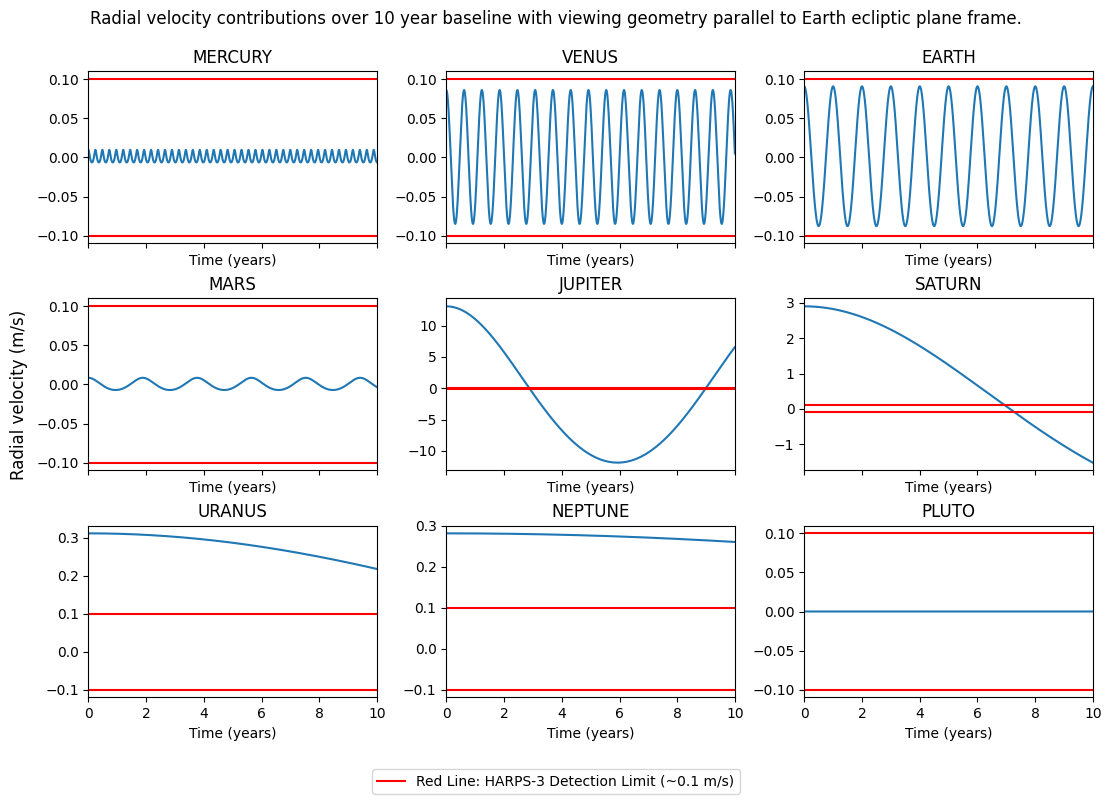

In [13]:
import matplotlib.pyplot as plt

HARPS3_LIMIT = 0.1   # m/s

# Convert time back to days
time_years = time / (24 * 60 * 60 * 365)

fig, axs = plt.subplots(3, 3, figsize=(11, 7), layout='constrained', sharex=True)

limit_line = None
for ax, planet in zip(axs.flat, planets):
  ax.set_title(planet)
  ax.set_xlabel('Time (years)')
  ax.plot(time_years, radial_velocity[planets.index(planet)])
  limit_line = ax.axhline(y=0.1, color='r', linestyle='-', label='HARPS-3 Detection Limit (0.1 m/s)')
  ax.axhline(y=-0.1, color='r', linestyle='-')

# Add legend outside the subplots to explain the detection threshold
fig.legend(
    handles=[limit_line],
    labels=['Red Line: HARPS-3 Detection Limit (~0.1 m/s)'],
    loc='lower center',
    bbox_to_anchor=(0.5, -0.08),
    fontsize=10,
    frameon=True
)
fig.supylabel('Radial velocity (m/s)')
fig.suptitle('Radial velocity contributions over 10 year baseline with viewing geometry parallel to Earth ecliptic plane frame.', y=1.05)
plt.xlim([0, 10])
plt.show()

# Combining radial velocities.

With $n_{p}$ planets, the radial velocity of the star to first order (neglecting planet-planet interaction) can be generalised as:

\begin{equation}
  v_{r,\star}(t) = \sum_{j=1}^{n_{p}} K_{j}\left[ \cos (\omega_j + \theta_j(t)) + e_j \cos \omega_j \right] \tag{8}.
\end{equation}

where $K_j$, $e_j$, $\omega_j$ and $\theta_j(t)$ are the semi-amplitude, eccentricity, argument of
pericentre and true anomaly of planet $j$.


For our simulation of the solar system we set all $\omega_j$ as zero.

\begin{equation}
  v_{r,\star}(t) = \sum_j K_j\left[\cos\theta_j(t) + e_j\right]. \tag{9}
\end{equation}

This sum treats each planet as orbiting the Sun independently and ignores planet–planet
interactions, which are negligible over a 10-year baseline.

In [14]:
def summed_rv(exclude=()):
    """Total solar RV (Eq. 8 with ω_j = 0), excluding the named planets."""
    keep = [name not in exclude for name in planets]
    return radial_velocity[keep].sum(axis=0)


rv_cases = {
    'all planets':                  summed_rv(),
    'excluding Jupiter':            summed_rv(exclude={'JUPITER'}),
    'excluding Jupiter and Saturn': summed_rv(exclude={'JUPITER', 'SATURN'}),
}

### Including and excluding Jupiter.

The Sun's total reflex RV is the sum of each planet's contribution. Jupiter dominates at about
12.5 m/s, so we also remove it, and then both Jupiter and Saturn, to show the much smaller signals
from the remaining planets.

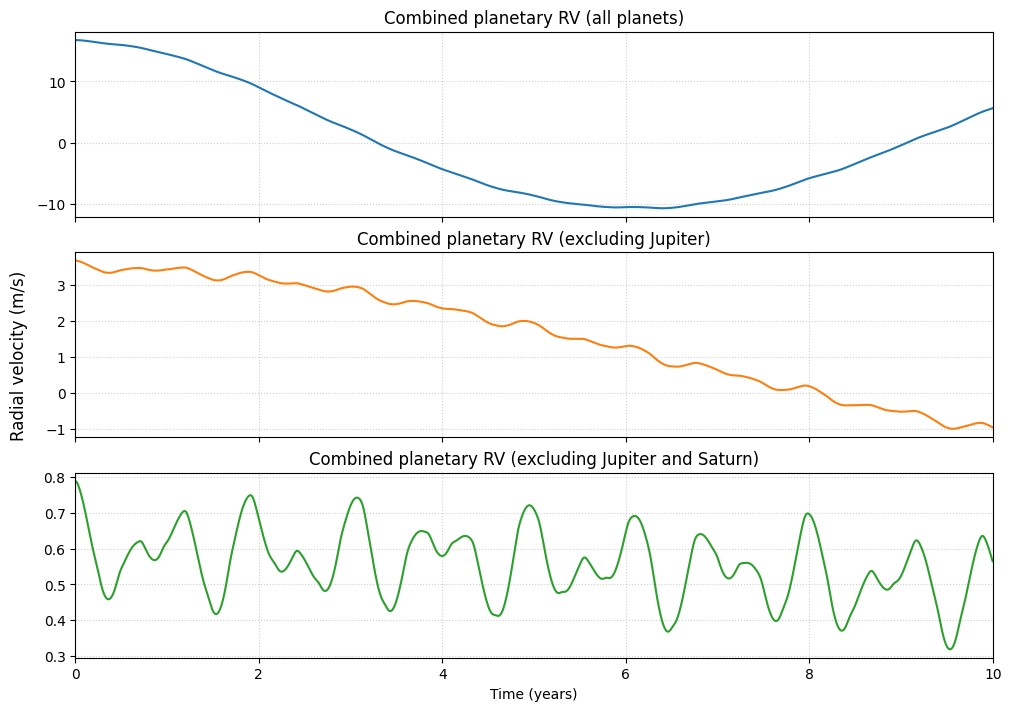

In [21]:
fig, axs = plt.subplots(len(rv_cases), 1, figsize=(10, 7), sharex=True, layout='constrained')

for ax, (label, rv), colour in zip(axs, rv_cases.items(), ['C0', 'C1', 'C2']):
    ax.plot(time_years, rv, color=colour)
    ax.set_title(f'Combined planetary RV ({label})')
    ax.grid(True, ls=':', alpha=0.6)

axs[-1].set_xlabel('Time (years)')
axs[-1].set_xlim(0, 10)
fig.supylabel('Radial velocity (m/s)')
plt.show()


# Measuring doppler shifting

An instantaneous measurement of the stellar radial velocity about the star–planet barycentre is given by the small, systematic Doppler shift in wavelength of the many absorption lines that make up the star’s spectrum.

For a source moving with speed $v$ at angle $\alpha$ to our line of sight (measured in the observer's frame),
the relativistic Doppler formula gives

\begin{equation}
  \lambda_{\rm obs} = \lambda_{\rm em}\,\frac{1 + \beta\cos\alpha}{\sqrt{1 - \beta^2}},
  \qquad \beta = \frac{v}{c}. \tag{9}
\end{equation}

For $\beta \ll 1$ we expand to first order. Since $v\cos\alpha = v_r$, this gives the classical result

\begin{equation}
  \frac{\Delta\lambda}{\lambda_{\rm em}} \equiv \frac{\lambda_{\rm obs} - \lambda_{\rm em}}{\lambda_{\rm em}}
  \approx \frac{v_r}{c}. \tag{10}
\end{equation}

Every line moves by the same $\Delta\lambda/\lambda$, and even with Jupiter and Saturn $v_r \sim 10$ m/s gives $\Delta\lambda/\lambda \sim 3\times10^{-8}$, which is why extreme-precision spectrographs average over thousands of lines. .

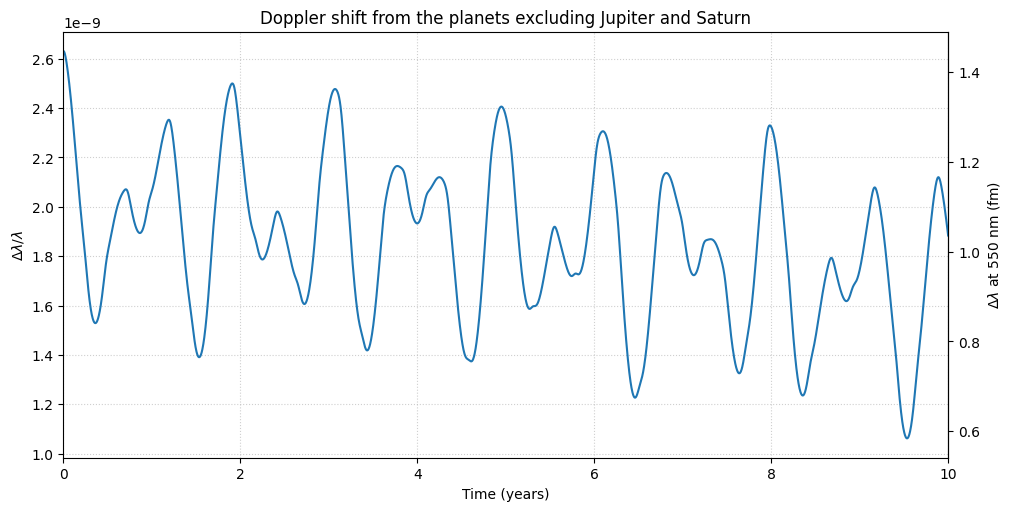

In [23]:
C = 2.998e8               # speed of light [m/s]
LAMBDA_REF = 550e-9       # reference line, mid-visible [m]

rv_no_giants = rv_cases['excluding Jupiter and Saturn']   # or summed_no_gas
frac_shift = rv_no_giants / C                              # Eq. (10), dimensionless
delta_lambda_fm = frac_shift * LAMBDA_REF * 1e15           # absolute shift at 550 nm [fm]

fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
ax.plot(time_years, frac_shift)
ax.set_title('Doppler shift from the planets excluding Jupiter and Saturn')
ax.set_xlabel('Time (years)')
ax.set_ylabel(r'$\Delta\lambda / \lambda$')
ax.set_xlim(0, 10)
ax.grid(True, ls=':', alpha=0.6)

sec = ax.secondary_yaxis('right', functions=(lambda f: f * LAMBDA_REF * 1e15,
                                             lambda d: d / (LAMBDA_REF * 1e15)))
sec.set_ylabel(r'$\Delta\lambda$ at 550 nm (fm)')
plt.show()


We have now simulated the reflex motion of our Sun due to the planets we know and love! Finally, we save these results for use in the next notebook. There we add stellar activity to the RV signals: it is one of the main obstacles to detecting Earth-like planets in the Terra Hunting Experiment ([THE](https://www.terrahunting.org/index.html)).

In [ ]:
np.savez('solar_system_rvs.npz',
         time=time, planets=planets, radial_velocity=radial_velocity,
         semi_amplitudes=semi_amplitudes, P=P, e=e, m_p=m_p)

# References

[[1]](https://doi.org/10.1017/CBO9780511994852) - Perryman, Michael. The Exoplanet Handbook. 1st ed. Cambridge University Press, 2011.

# Acknowledgements